In [1]:
import pandas as pd
import numpy as np


In [2]:
df1 = pd.read_csv("2025_scores.csv")
df2 = pd.read_csv("2024_scores.csv")


In [3]:
df1.head()


,Season,Week,GameStatus,GameSlot,GameDate,AwayTeam,AwayScore,HomeTeam,HomeScore
0,2025,HALL OF FAME,FINAL,Thursday,July 31st,LAC,34.0,DET,7.0
1,2025,PRESEASON WEEK 1,FINAL,Thursday,August 7th,IND,16.0,BAL,24.0
2,2025,PRESEASON WEEK 1,FINAL,Thursday,August 7th,CIN,27.0,PHI,34.0
3,2025,PRESEASON WEEK 1,FINAL,Thursday,August 7th,LV,23.0,SEA,23.0
4,2025,PRESEASON WEEK 1,FINAL,Friday,August 8th,DET,17.0,ATL,10.0


In [4]:
df2.tail()


,Season,Week,GameStatus,GameSlot,GameDate,AwayTeam,AwayScore,HomeTeam,HomeScore
363,2024,DIVISIONAL PLAYOFFS,FINAL,Sunday,January 19th,LAR,22.0,PHI,28.0
364,2024,DIVISIONAL PLAYOFFS,FINAL,Sunday,January 19th,BAL,25.0,BUF,27.0
365,2024,CONFERENCE CHAMPIONSHIPS,FINAL,Sunday,January 26th,WAS,23.0,PHI,55.0
366,2024,CONFERENCE CHAMPIONSHIPS,FINAL,Sunday,January 26th,BUF,29.0,KC,32.0
367,2024,SUPER BOWL,FINAL,Sunday,February 9th,KC,22.0,PHI,40.0


In [5]:
df1 = df1[~df1['Week'].str.contains('HALL OF FAME|PRESEASON|PLAYOFFS|CHAMPIONSHIPS|SUPER BOWL|WILD CARD WEEKEND', na=False)]
df2 = df2[~df2['Week'].str.contains('HALL OF FAME|PRESEASON|PLAYOFFS|CHAMPIONSHIPS|SUPER BOWL|WILD CARD WEEKEND', na=False)]


In [6]:
df1.tail()


,Season,Week,GameStatus,GameSlot,GameDate,AwayTeam,AwayScore,HomeTeam,HomeScore
348,2025,WEEK 18,FINAL,Sunday,January 4th,ARI,20.0,LAR,37.0
349,2025,WEEK 18,FINAL,Sunday,January 4th,KC,12.0,LV,14.0
350,2025,WEEK 18,FINAL,Sunday,January 4th,MIA,10.0,NE,38.0
351,2025,WEEK 18,FINAL,Sunday,January 4th,WAS,24.0,PHI,17.0
352,2025,WEEK 18,FINAL,Sunday Night Football,January 4th,BAL,24.0,PIT,26.0


In [7]:
cold_teams = ['BUF', 'GB', 'CHI', 'CLE', 'PIT', 'DEN', 'KC', 'NE', 'NYG', 'NYJ', 'CIN']

df1['GameDateParsed'] = pd.to_datetime(
    df1['GameDate'].str.replace(r'(\d+)(st|nd|rd|th)$', r'\1', regex=True),
    format='%B %d',
    errors='coerce'
)

df1['ColdGame'] = df1.apply(
    lambda row: 'YES'
    if row['HomeTeam'] in cold_teams and
       (row['GameDateParsed'].month >= 11 or row['GameDateParsed'].month <= 1)
    else 'NO',
    axis=1
)


In [8]:
df1.tail(20)


,Season,Week,GameStatus,GameSlot,GameDate,AwayTeam,AwayScore,HomeTeam,HomeScore,GameDateParsed,ColdGame
333,2025,WEEK 17,FINAL,Sunday,December 28th,NYG,34.0,LV,10.0,1900-12-28,NO
334,2025,WEEK 17,FINAL,Sunday,December 28th,PHI,13.0,BUF,12.0,1900-12-28,YES
335,2025,WEEK 17,FINAL,Sunday Night Football,December 28th,CHI,38.0,SF,42.0,1900-12-28,NO
336,2025,WEEK 17,FINAL,Monday Night Football,December 29th,LAR,24.0,ATL,27.0,1900-12-29,NO
337,2025,WEEK 18,FINAL,Saturday,January 3rd,CAR,14.0,TB,16.0,1900-01-03,NO
338,2025,WEEK 18,FINAL,Saturday,January 3rd,SEA,13.0,SF,3.0,1900-01-03,NO
339,2025,WEEK 18,FINAL,Sunday,January 4th,NO,17.0,ATL,19.0,1900-01-04,NO
340,2025,WEEK 18,FINAL,Sunday,January 4th,CLE,20.0,CIN,18.0,1900-01-04,YES
341,2025,WEEK 18,FINAL,Sunday,January 4th,IND,30.0,HOU,38.0,1900-01-04,NO
342,2025,WEEK 18,FINAL,Sunday,January 4th,TEN,7.0,JAX,41.0,1900-01-04,NO


In [9]:
df_all = pd.concat([df1, df2], ignore_index=True, sort=False)

if 'GameDateParsed' not in df_all.columns or df_all['GameDateParsed'].isna().any():
    df_all['GameDateParsed'] = pd.to_datetime(
        df_all['GameDate'].str.replace(r'(\d+)(st|nd|rd|th)$', r'\1', regex=True),
        format='%B %d',
        errors='coerce'
    )

if 'ColdGame' not in df_all.columns or df_all['ColdGame'].isna().any():
    df_all['ColdGame'] = df_all.apply(
        lambda row: 'YES'
        if row['HomeTeam'] in cold_teams and
           pd.notna(row['GameDateParsed']) and
           (row['GameDateParsed'].month >= 11 or row['GameDateParsed'].month <= 1)
        else 'NO',
        axis=1
    )

teams = pd.unique(df_all[['HomeTeam', 'AwayTeam']].values.ravel())
stats = []

for team in teams:
    team_games = df_all[(df_all['HomeTeam'] == team) | (df_all['AwayTeam'] == team)].copy()
    if team_games.empty:
        continue

    team_games['TeamScore'] = np.where(team_games['HomeTeam'] == team, team_games['HomeScore'], team_games['AwayScore'])
    team_games['OppScore'] = np.where(team_games['HomeTeam'] == team, team_games['AwayScore'], team_games['HomeScore'])
    team_games['Win'] = team_games['TeamScore'] > team_games['OppScore']
    team_games['Tie'] = team_games['TeamScore'] == team_games['OppScore']

    overall_games = len(team_games)
    overall_wins = int(team_games['Win'].sum())
    overall_pts_for = float(team_games['TeamScore'].mean())
    overall_pts_against = float(team_games['OppScore'].mean())
    overall_win_rate = float(team_games['Win'].mean())

    cold_games = team_games[team_games['ColdGame'] == 'YES']
    cold_count = len(cold_games)

    if cold_count > 0:
        cold_wins = int(cold_games['Win'].sum())
        cold_pts_for = float(cold_games['TeamScore'].mean())
        cold_pts_against = float(cold_games['OppScore'].mean())
        cold_win_rate = float(cold_games['Win'].mean())
    else:
        cold_wins = 0
        cold_pts_for = np.nan
        cold_pts_against = np.nan
        cold_win_rate = np.nan

    stats.append({
        'Team': team,
        'OverallGames': overall_games,
        'OverallWins': overall_wins,
        'OverallWinRate': overall_win_rate,
        'OverallPointsFor': overall_pts_for,
        'OverallPointsAgainst': overall_pts_against,
        'ColdGames': cold_count,
        'ColdWins': cold_wins,
        'ColdWinRate': cold_win_rate,
        'ColdPointsFor': cold_pts_for,
        'ColdPointsAgainst': cold_pts_against,
    })

stats_df = pd.DataFrame(stats)
stats_df['WinRateDelta'] = stats_df['ColdWinRate'] - stats_df['OverallWinRate']
stats_df['PointsForDelta'] = stats_df['ColdPointsFor'] - stats_df['OverallPointsFor']
stats_df['PointsAgainstDelta'] = stats_df['ColdPointsAgainst'] - stats_df['OverallPointsAgainst']

outliers = stats_df[
    (stats_df['ColdGames'] >= 2) &
    (
        (stats_df['WinRateDelta'] <= -0.3) |
        (stats_df['PointsForDelta'] <= -7)
    )
].sort_values(['WinRateDelta', 'PointsForDelta'])

outliers[[
    'Team', 'ColdGames',
    'OverallWinRate', 'ColdWinRate', 'WinRateDelta',
    'OverallPointsFor', 'ColdPointsFor', 'PointsForDelta',
    'OverallPointsAgainst', 'ColdPointsAgainst', 'PointsAgainstDelta'
]]


,Team,ColdGames,OverallWinRate,ColdWinRate,WinRateDelta,OverallPointsFor,ColdPointsFor,PointsForDelta,OverallPointsAgainst,ColdPointsAgainst,PointsAgainstDelta
4,ATL,3,0.444444,0.0,-0.444444,21.823529,17.666667,-4.156863,24.235294,29.666667,5.431373
14,NO,2,0.305556,0.5,0.194444,18.941176,7.000000,-11.941176,22.970588,22.500000,-0.470588
0,PHI,2,0.694444,1.0,0.305556,24.764706,11.500000,-13.264706,18.470588,9.500000,-8.970588
22,SEA,2,0.666667,1.0,0.333333,25.235294,16.000000,-9.235294,19.411765,12.000000,-7.411765


In [10]:
from nfl_model_pipeline import load_team_stats


team_week_raw = load_team_stats([2023, 2024, 2025])
team_week_2023 = team_week_raw.loc[team_week_raw.season.eq(2023)].copy()
team_week_2024 = team_week_raw.loc[team_week_raw.season.eq(2024)].copy()
team_week_2025 = team_week_raw.loc[team_week_raw.season.eq(2025)].copy()
team_week = team_week_raw.loc[team_week_raw.season_type.eq('REG')].copy()

cols = ['team', 'season', 'week', 'game_id', 'opponent_team',
        'passing_epa', 'rushing_epa', 'passing_cpoe',
        'passing_interceptions', 'fumbles_lost_total', 'def_interceptions',
        'def_sacks', 'def_qb_hits', 'sacks_suffered']
team_week = team_week[cols].copy()
sacks_lookup = team_week.set_index(['game_id', 'team'])['sacks_suffered']
team_week['sacks_for'] = team_week.apply(
    lambda r: sacks_lookup.get((r['game_id'], r['opponent_team']), np.nan), axis=1
)
team_week.head()


,team,season,week,game_id,opponent_team,passing_epa,rushing_epa,passing_cpoe,passing_interceptions,fumbles_lost_total,def_interceptions,def_sacks,def_qb_hits,sacks_suffered,sacks_for
0,ARI,2023,1,2023_01_ARI_WAS,WAS,-9.239668,-11.179296,2.031421,0,2,1,6,6,3,6
1,ATL,2023,1,2023_01_CAR_ATL,CAR,-4.450450,-0.595772,6.426090,0,0,2,2,8,4,2
2,BAL,2023,1,2023_01_HOU_BAL,HOU,-4.415663,1.208152,11.384226,1,1,0,5,10,4,5
3,BUF,2023,1,2023_01_BUF_NYJ,NYJ,-1.409397,-3.168568,7.830620,3,1,1,3,8,5,3
4,CAR,2023,1,2023_01_CAR_ATL,ATL,-10.528563,-8.897445,-5.514066,2,1,0,4,5,2,4


In [11]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)


In [12]:
team_week_2024.head()


,season,week,team,season_type,game_id,opponent_team,completions,attempts,passing_yards,passing_tds,passing_interceptions,sacks_suffered,sack_yards_lost,sack_fumbles,sack_fumbles_lost,passing_air_yards,passing_yards_after_catch,passing_first_downs,passing_epa,passing_cpoe,passing_2pt_conversions,passing_10,passing_16,passing_20,passing_40,carries,rushing_yards,rushing_tds,rushing_fumbles,rushing_fumbles_lost,rushing_first_downs,rushing_epa,rushing_2pt_conversions,rushing_10,rushing_12,rushing_20,rushing_40,receptions,targets,receiving_yards,receiving_tds,receiving_fumbles,receiving_fumbles_lost,receiving_air_yards,receiving_yards_after_catch,receiving_first_downs,receiving_epa,receiving_2pt_conversions,receiving_10,receiving_16,receiving_20,receiving_40,special_teams_tds,def_tackles_solo,def_tackles_with_assist,def_tackle_assists,def_tackles_for_loss,def_tackles_for_loss_yards,def_fumbles_forced,def_sacks,def_sack_yards,def_qb_hits,def_interceptions,def_interception_yards,def_pass_defended,def_tds,def_fumbles,def_safeties,def_punt_blocks,def_pat_blocks,def_fg_blocks,def_2pt_atts,def_2pt_made,misc_yards,fumble_recovery_own,fumble_recovery_yards_own,fumble_recovery_opp,fumble_recovery_yards_opp,fumble_recovery_tds,penalties,penalty_yards,timeouts,fumbles_forced_by_opp,fumbles_not_forced,fumbles_out_of_bounds,fumbles_total,fumbles_lost_total,punt_returns,punt_return_yards,kickoff_returns,kickoff_return_yards,fg_made,fg_att,fg_missed,fg_blocked,fg_long,fg_pct,fg_made_0_19,fg_made_20_29,fg_made_30_39,fg_made_40_49,fg_made_50_59,fg_made_60_,fg_missed_0_19,fg_missed_20_29,fg_missed_30_39,fg_missed_40_49,fg_missed_50_59,fg_missed_60_,fg_made_list,fg_missed_list,fg_blocked_list,fg_made_distance,fg_missed_distance,fg_blocked_distance,pat_made,pat_att,pat_missed,pat_blocked,pat_pct,gwfg_made,gwfg_att,gwfg_missed,gwfg_blocked,gwfg_distance,pt_att,pt_blocked,pt_long,pt_yards,pt_inside_20,pt_out_of_bounds,pt_downed,pt_touchback,pt_fair_caught,pt_returned,pt_return_yards,pt_return_tds,pt_net_yards
570,2024,1,ARI,REG,2024_01_ARI_BUF,BUF,21,31,162,1,0,4,-16,1,1,191,100,10,-1.184850,1.196628,0,4,2,2,0,25,124,1,0,0,7,4.984950,1,4,3,2,0,21,31,162,1,0,0,191,100,10,8.129718,0,4,2,2,0,1,29,14,28,5,18,1,2,10,3,0,0,2,0,0,0,0,0,0,0,0,0,0,0,1,0,0,5,31,1,1,0,0,1,1,1,6,3,123,2,2,0,0,31.0,1.000000,0,1,1,0,0,0,0,0,0,0,0,0,29;31,NaN,NaN,60,0,0,2,2,0,0,1.0,0,0,0,0,0,2,0,50.0,78,0,1,0,0,0,1,7,0,71
571,2024,1,ATL,REG,2024_01_PIT_ATL,PIT,16,26,155,1,2,2,-18,0,0,140,73,8,-11.084853,-1.985487,0,5,2,1,0,22,89,0,0,0,6,-6.224773,0,3,2,0,0,16,23,155,1,0,0,140,73,8,-7.576804,0,5,2,1,0,0,45,9,29,7,36,0,2,23,5,0,0,1,0,0,0,0,0,0,0,0,0,0,-6,0,0,0,5,34,6,0,1,0,1,1,2,28,2,56,1,1,0,0,24.0,1.000000,0,1,0,0,0,0,0,0,0,0,0,0,24,NaN,NaN,24,0,0,1,1,0,0,1.0,0,0,0,0,0,4,0,59.0,210,0,0,0,0,0,4,47,0,163
572,2024,1,BAL,REG,2024_01_BAL_KC,KC,26,41,273,1,0,1,-6,1,1,267,166,11,-2.491160,-3.686818,0,8,5,2,1,32,185,1,0,0,13,8.459208,0,5,3,0,0,26,40,273,1,0,0,267,166,11,3.723055,0,8,5,2,1,0,28,4,20,2,12,0,2,10,7,1,0,4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,7,64,7,1,0,0,1,1,1,3,0,0,2,3,1,0,32.0,0.666667,0,1,1,0,0,0,0,0,0,0,1,0,25;32,53,NaN,57,53,0,2,2,0,0,1.0,0,0,0,0,0,2,0,40.0,75,2,0,0,0,2,0,0,0,75
573,2024,1,BUF,REG,2024_01_ARI_BUF,ARI,18,23,232,2,0,2,-10,1,1,166,125,11,9.161098,9.891942,0,12,5,3,0,33,130,2,0,0,8,3.497710,0,2,2,0,0,18,23,232,2,0,0,166,125,11,15.683219,0,12,5,3,0,0,38,7,17,4,19,1,4,16,5,0,0,3,0,0,0,0,0,0,0,0,0,0,0,1,0,0,9,65,3,1,0,0,1,1,1,7,1,53,2,2,0,0,39.0,1.000000,0,0,2,0,0,0,0,0,0,0,0,0,37;39,NaN,NaN,76,0,0,4,4,0,0,1.0,0,0,0,0,0,2,0,51.0,85,1,0,1,0,0,1,6,0,79
574,2024,1,CAR,REG,2024_01_CAR_NO,NO,13,31,161,0,2,4,-26,0,0,383,50,7,-18.467295,-17.186285,0,6,3,2,0,20,58,1,1,1,2,-8.230615,0,0,0,0,0,13,29,161,0,0,0,383,50,7,-10.917299,0,6,3,2,0,0,40,6,30,6,17,0,1,1,1,0,0,3,0,0,0,0,0,0,0,0,0,0,0,1,0,0,6,80,4,1,0,0,1,1,0,0,9,232,1,1,0,0,43.0,1.000000,0,0,0,1,0,0,0,0,0,0,0,0,43,NaN,NaN,43,0,0,1,1,0,0,1.0,0,0,0,0,0,5,0,53.0,191,0,0,1,0,0,4,60,0,131


In [13]:
pd.set_option('display.max_seq_items', None)
pd.set_option('display.max_columns', None)

team_week_2024.columns


Index(['season', 'week', 'team', 'season_type', 'game_id', 'opponent_team',
       'completions', 'attempts', 'passing_yards', 'passing_tds',
       'passing_interceptions', 'sacks_suffered', 'sack_yards_lost',
       'sack_fumbles', 'sack_fumbles_lost', 'passing_air_yards',
       'passing_yards_after_catch', 'passing_first_downs', 'passing_epa',
       'passing_cpoe', 'passing_2pt_conversions', 'passing_10', 'passing_16',
       'passing_20', 'passing_40', 'carries', 'rushing_yards', 'rushing_tds',
       'rushing_fumbles', 'rushing_fumbles_lost', 'rushing_first_downs',
       'rushing_epa', 'rushing_2pt_conversions', 'rushing_10', 'rushing_12',
       'rushing_20', 'rushing_40', 'receptions', 'targets', 'receiving_yards',
       'receiving_tds', 'receiving_fumbles', 'receiving_fumbles_lost',
       'receiving_air_yards', 'receiving_yards_after_catch',
       'receiving_first_downs', 'receiving_epa', 'receiving_2pt_conversions',
       'receiving_10', 'receiving_16', 'receiving_20', 

In [14]:
print(team_week.columns.tolist())


['team', 'season', 'week', 'game_id', 'opponent_team', 'passing_epa', 'rushing_epa', 'passing_cpoe', 'passing_interceptions', 'fumbles_lost_total', 'def_interceptions', 'def_sacks', 'def_qb_hits', 'sacks_suffered', 'sacks_for']


In [15]:
team_week.head()


,team,season,week,game_id,opponent_team,passing_epa,rushing_epa,passing_cpoe,passing_interceptions,fumbles_lost_total,def_interceptions,def_sacks,def_qb_hits,sacks_suffered,sacks_for
0,ARI,2023,1,2023_01_ARI_WAS,WAS,-9.239668,-11.179296,2.031421,0,2,1,6,6,3,6
1,ATL,2023,1,2023_01_CAR_ATL,CAR,-4.450450,-0.595772,6.426090,0,0,2,2,8,4,2
2,BAL,2023,1,2023_01_HOU_BAL,HOU,-4.415663,1.208152,11.384226,1,1,0,5,10,4,5
3,BUF,2023,1,2023_01_BUF_NYJ,NYJ,-1.409397,-3.168568,7.830620,3,1,1,3,8,5,3
4,CAR,2023,1,2023_01_CAR_ATL,ATL,-10.528563,-8.897445,-5.514066,2,1,0,4,5,2,4


In [16]:
feature_cols = [
    'passing_epa',
    'rushing_epa',
    'passing_cpoe',
    'passing_interceptions',
    'fumbles_lost_total',
    'def_interceptions',
    'def_sacks',
    'def_qb_hits',
    'sacks_suffered',
    'sacks_for',
]

team_features = team_week.copy()


numeric_cols = ['season', 'week'] + feature_cols
team_features[numeric_cols] = team_features[numeric_cols].apply(
    pd.to_numeric, errors='raise'
)

assert team_features[['season', 'team', 'week']].notna().all().all()
assert not team_features.duplicated(['season', 'team', 'week']).any()

team_features = team_features.sort_values(
    ['season', 'team', 'week']
).reset_index(drop=True)


grouped = team_features.groupby(['season', 'team'], sort=False)

team_features['prior_games'] = grouped.cumcount()

for feature in feature_cols:
    team_features[f'{feature}_pregame_avg'] = grouped[feature].transform(
        lambda values: values.shift(1).expanding(min_periods=1).mean()
    )


team_features_2023 = team_features.loc[team_features['season'].eq(2023)].copy()
team_features_2024 = team_features.loc[team_features['season'].eq(2024)].copy()
team_features_2025 = team_features.loc[team_features['season'].eq(2025)].copy()


team_features.loc[
    (team_features['team'] == 'BUF')
    & (team_features['season'] == 2025),
    [
        'season', 'week', 'team', 'prior_games',
        'def_sacks', 'def_sacks_pregame_avg',
        'def_interceptions', 'def_interceptions_pregame_avg',
    ]
]


,season,week,team,prior_games,def_sacks,def_sacks_pregame_avg,def_interceptions,def_interceptions_pregame_avg
1139,2025,1,BUF,0,2,NaN,0,NaN
1140,2025,2,BUF,1,4,2.000000,0,0.000000
1141,2025,3,BUF,2,0,3.000000,1,0.000000
1142,2025,4,BUF,3,3,2.000000,1,0.333333
1143,2025,5,BUF,4,4,2.250000,0,0.500000
1144,2025,6,BUF,5,2,2.600000,0,0.400000
1145,2025,8,BUF,6,7,2.500000,1,0.333333
1146,2025,9,BUF,7,3,3.142857,1,0.428571
1147,2025,10,BUF,8,0,3.125000,2,0.500000
1148,2025,11,BUF,9,1,2.777778,1,0.666667


In [17]:
def clean_score_games(df):
    regular = df['Week'].str.fullmatch(r'WEEK \d+', na=False)
    completed = df['GameStatus'].eq('FINAL')
    df = df.loc[regular & completed].copy()

    required = ['Season', 'AwayTeam', 'HomeTeam', 'AwayScore', 'HomeScore']
    assert df[required].notna().all().all(), 'Missing game information'

    df['Season'] = pd.to_numeric(df['Season'], errors='raise').astype(int)
    df['WeekNum'] = (
        df['Week'].str.extract(r'(\d+)', expand=False).astype(int)
    )
    df[['AwayScore', 'HomeScore']] = df[['AwayScore', 'HomeScore']].apply(
        pd.to_numeric, errors='raise'
    )


    dates = df['GameDate'].str.replace(
        r'(\d+)(st|nd|rd|th)', r'\1', regex=True
    )
    years = (
        df['Season']
        + dates.str.match(r'January|February').astype(int)
    )

    df['GameDateParsed'] = pd.to_datetime(
        dates + ' ' + years.astype(str),
        format='%B %d %Y',
        errors='raise'
    )


    df['ColdGame'] = np.where(
        df['HomeTeam'].isin(cold_teams)
        & df['GameDateParsed'].dt.month.isin([11, 12, 1]),
        'YES',
        'NO'
    )

    return df.sort_values(
        ['Season', 'WeekNum', 'GameDateParsed']
    ).reset_index(drop=True)


df1 = clean_score_games(df1)
df2 = clean_score_games(df2)

print(f"2025: {len(df1)} games")
print(f"2024: {len(df2)} games")


2025: 272 games
2024: 272 games


In [18]:
def add_pregame_ppg(df):
    df = df.copy()

    scored, allowed, played = {}, {}, {}
    output = {
        name: []
        for name in ['awayPPG', 'homePPG', 'awayPAPG', 'homePAPG']
    }

    for _, row in df.iterrows():
        for side, team_col, score_col, opponent_score_col in [
            ('away', 'AwayTeam', 'AwayScore', 'HomeScore'),
            ('home', 'HomeTeam', 'HomeScore', 'AwayScore'),
        ]:
            key = (row['Season'], row[team_col])
            n = played.get(key, 0)


            output[f'{side}PPG'].append(
                scored[key] / n if n else np.nan
            )
            output[f'{side}PAPG'].append(
                allowed[key] / n if n else np.nan
            )

            scored[key] = scored.get(key, 0.0) + row[score_col]
            allowed[key] = (
                allowed.get(key, 0.0) + row[opponent_score_col]
            )
            played[key] = n + 1

    for column, values in output.items():
        df[column] = values

    return df


df1 = add_pregame_ppg(df1)
df2 = add_pregame_ppg(df2)


In [19]:
df_all = pd.concat([df2, df1], ignore_index=True)

ppg_cols = ['awayPPG', 'homePPG', 'awayPAPG', 'homePAPG']

assert not df_all.duplicated(
    ['Season', 'WeekNum', 'AwayTeam', 'HomeTeam']
).any(), 'Duplicate games found'

assert df_all.loc[
    df_all['WeekNum'].eq(1), ppg_cols
].isna().all().all(), 'Week 1 should have no prior-game averages'

assert df_all.loc[
    df_all['WeekNum'].gt(1), ppg_cols
].notna().all().all(), 'Unexpected missing averages after Week 1'

print(df_all.groupby('Season').size().rename('completed_games'))

df_all.loc[
    df_all['WeekNum'].between(1, 3),
    ['Season', 'WeekNum', 'AwayTeam', 'HomeTeam'] + ppg_cols
]


Season
2024    272
2025    272
Name: completed_games, dtype: int64


,Season,WeekNum,AwayTeam,HomeTeam,awayPPG,homePPG,awayPAPG,homePAPG
0,2024,1,BAL,KC,NaN,NaN,NaN,NaN
1,2024,1,GB,PHI,NaN,NaN,NaN,NaN
2,2024,1,PIT,ATL,NaN,NaN,NaN,NaN
3,2024,1,ARI,BUF,NaN,NaN,NaN,NaN
4,2024,1,TEN,CHI,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
315,2025,3,NO,SEA,17.0,22.0,23.0,17.0
316,2025,3,DAL,CHI,30.0,22.5,30.5,39.5
317,2025,3,ARI,SF,23.5,21.5,17.5,17.0
318,2025,3,KC,NYG,19.0,21.5,23.5,30.5


In [20]:
df3 = pd.read_csv("2023_scores.csv")
df3_rows_loaded = len(df3)

assert df3['Season'].eq(2023).all(), 'Unexpected season in 2023_scores.csv'

print(f"2023 rows loaded: {df3_rows_loaded}")
display(df3['GameStatus'].value_counts(dropna=False).rename('raw_rows'))
display(df3.head())


2023 rows loaded: 368


FINAL                334
BYE                   32
Clinched Playoffs      2
Name: raw_rows, dtype: int64

,Season,Week,GameStatus,GameSlot,GameDate,AwayTeam,AwayScore,HomeTeam,HomeScore
0,2023,HALL OF FAME,FINAL,Thursday,August 3rd,NYJ,16.0,CLE,21.0
1,2023,PRESEASON WEEK 1,FINAL,Thursday,August 10th,HOU,20.0,NE,9.0
2,2023,PRESEASON WEEK 1,FINAL,Thursday,August 10th,MIN,13.0,SEA,24.0
3,2023,PRESEASON WEEK 1,FINAL,Friday,August 11th,NYG,16.0,DET,21.0
4,2023,PRESEASON WEEK 1,FINAL,Friday,August 11th,PIT,27.0,TB,17.0


In [21]:
df3 = clean_score_games(df3)
df3 = add_pregame_ppg(df3)

assert not df3.duplicated(['Season', 'WeekNum', 'AwayTeam', 'HomeTeam']).any()
assert df3[['HomeTeam', 'AwayTeam', 'HomeScore', 'AwayScore', 'GameDateParsed']].notna().all().all()
assert df3['GameDateParsed'].is_monotonic_increasing

ppg_cols_2023 = ['awayPPG', 'homePPG', 'awayPAPG', 'homePAPG']
assert df3.loc[df3['WeekNum'].eq(1), ppg_cols_2023].isna().all().all()
assert df3.loc[df3['WeekNum'].gt(1), ppg_cols_2023].notna().all().all()

print(f"2023 completed regular-season games: {len(df3)}")
print(f"Rows excluded: {df3_rows_loaded - len(df3)}")
display(df3.head())
display(df3.tail())
display(df3[['AwayScore', 'HomeScore'] + ppg_cols_2023].describe())
display(df3.isna().sum().rename('missing_rows'))


2023 completed regular-season games: 272
Rows excluded: 96


,Season,Week,GameStatus,GameSlot,GameDate,AwayTeam,AwayScore,HomeTeam,HomeScore,WeekNum,GameDateParsed,ColdGame,awayPPG,homePPG,awayPAPG,homePAPG
0,2023,WEEK 1,FINAL,Sunday Night Football,September 7th,DET,21.0,KC,20.0,1,2023-09-07,NO,NaN,NaN,NaN,NaN
1,2023,WEEK 1,FINAL,Sunday,September 10th,CAR,10.0,ATL,24.0,1,2023-09-10,NO,NaN,NaN,NaN,NaN
2,2023,WEEK 1,FINAL,Sunday,September 10th,HOU,9.0,BAL,25.0,1,2023-09-10,NO,NaN,NaN,NaN,NaN
3,2023,WEEK 1,FINAL,Sunday,September 10th,CIN,3.0,CLE,24.0,1,2023-09-10,NO,NaN,NaN,NaN,NaN
4,2023,WEEK 1,FINAL,Sunday,September 10th,JAX,31.0,IND,21.0,1,2023-09-10,NO,NaN,NaN,NaN,NaN


,Season,Week,GameStatus,GameSlot,GameDate,AwayTeam,AwayScore,HomeTeam,HomeScore,WeekNum,GameDateParsed,ColdGame,awayPPG,homePPG,awayPAPG,homePAPG
267,2023,WEEK 18,FINAL,Sunday,January 7th,DEN,14.0,LV,27.0,18,2024-01-07,NO,21.4375,19.0625,24.1250,19.8125
268,2023,WEEK 18,FINAL,Sunday,January 7th,PHI,10.0,NYG,27.0,18,2024-01-07,YES,26.4375,14.9375,25.0625,24.8125
269,2023,WEEK 18,FINAL,Sunday,January 7th,LAR,21.0,SF,20.0,18,2024-01-07,NO,23.9375,29.4375,22.3125,17.3125
270,2023,WEEK 18,FINAL,Sunday,January 7th,DAL,38.0,WAS,10.0,18,2024-01-07,NO,29.4375,19.9375,19.0625,30.0000
271,2023,WEEK 18,FINAL,Sunday Night Football,January 7th,BUF,21.0,MIA,14.0,18,2024-01-07,NO,26.8750,30.1250,18.5625,23.1250


,AwayScore,HomeScore,awayPPG,homePPG,awayPAPG,homePAPG
count,272.000000,272.000000,256.000000,256.000000,256.000000,256.000000
mean,20.426471,23.110294,21.896497,21.792468,21.936664,21.718883
std,9.464349,10.393138,5.411429,5.493680,5.117349,4.532583
min,0.000000,0.000000,0.000000,3.000000,3.000000,0.000000
25%,14.000000,17.000000,18.486111,18.000000,19.191667,19.343750
50%,20.000000,23.000000,21.800000,21.683333,21.333333,21.422222
75%,27.000000,29.000000,25.000000,25.031250,24.425000,24.737500
max,45.000000,70.000000,43.333333,40.000000,40.666667,37.500000


Season             0
Week               0
GameStatus         0
GameSlot           0
GameDate           0
AwayTeam           0
AwayScore          0
HomeTeam           0
HomeScore          0
WeekNum            0
GameDateParsed     0
ColdGame           0
awayPPG           16
homePPG           16
awayPAPG          16
homePAPG          16
Name: missing_rows, dtype: int64

In [22]:
team_games_2023 = pd.concat([
    df3[['HomeTeam', 'HomeScore', 'AwayScore', 'ColdGame']].rename(
        columns={'HomeTeam': 'Team', 'HomeScore': 'TeamScore', 'AwayScore': 'OppScore'}
    ),
    df3[['AwayTeam', 'AwayScore', 'HomeScore', 'ColdGame']].rename(
        columns={'AwayTeam': 'Team', 'AwayScore': 'TeamScore', 'HomeScore': 'OppScore'}
    ),
], ignore_index=True)

team_games_2023['Win'] = team_games_2023['TeamScore'] > team_games_2023['OppScore']
team_games_2023['Tie'] = team_games_2023['TeamScore'] == team_games_2023['OppScore']

stats_df_2023 = team_games_2023.groupby('Team').agg(
    OverallGames=('Win', 'size'),
    OverallWins=('Win', 'sum'),
    OverallTies=('Tie', 'sum'),
    OverallWinRate=('Win', 'mean'),
    OverallPointsFor=('TeamScore', 'mean'),
    OverallPointsAgainst=('OppScore', 'mean'),
)

cold_stats_2023 = team_games_2023.loc[
    team_games_2023['ColdGame'].eq('YES')
].groupby('Team').agg(
    ColdGames=('Win', 'size'),
    ColdWins=('Win', 'sum'),
    ColdWinRate=('Win', 'mean'),
    ColdPointsFor=('TeamScore', 'mean'),
    ColdPointsAgainst=('OppScore', 'mean'),
)

stats_df_2023 = stats_df_2023.join(cold_stats_2023).reset_index()
stats_df_2023[['ColdGames', 'ColdWins']] = (
    stats_df_2023[['ColdGames', 'ColdWins']].fillna(0).astype(int)
)

stats_df_2023['WinRateDelta'] = stats_df_2023['ColdWinRate'] - stats_df_2023['OverallWinRate']
stats_df_2023['PointsForDelta'] = stats_df_2023['ColdPointsFor'] - stats_df_2023['OverallPointsFor']
stats_df_2023['PointsAgainstDelta'] = stats_df_2023['ColdPointsAgainst'] - stats_df_2023['OverallPointsAgainst']

outliers_2023 = stats_df_2023.loc[
    stats_df_2023['ColdGames'].ge(2)
    & (
        stats_df_2023['WinRateDelta'].le(-0.3)
        | stats_df_2023['PointsForDelta'].le(-7)
    )
].sort_values(['WinRateDelta', 'PointsForDelta'])

assert len(stats_df_2023) == 32
assert stats_df_2023['OverallGames'].eq(17).all()
assert stats_df_2023['OverallGames'].sum() == 2 * len(df3)

print("2023 overall and cold-game summaries (same cold-game definition):")
display(stats_df_2023.sort_values('OverallWinRate', ascending=False))
print("2023 cold-game outliers using the existing thresholds:")
display(outliers_2023)


2023 overall and cold-game summaries (same cold-game definition):


,Team,OverallGames,OverallWins,OverallTies,OverallWinRate,OverallPointsFor,OverallPointsAgainst,ColdGames,ColdWins,ColdWinRate,ColdPointsFor,ColdPointsAgainst,WinRateDelta,PointsForDelta,PointsAgainstDelta
2,BAL,17,13,0,0.764706,28.411765,16.470588,0,0,NaN,NaN,NaN,NaN,NaN,NaN
8,DAL,17,12,0,0.705882,29.941176,18.529412,1,0,0.000000,10.000000,31.000000,-0.705882,-19.941176,12.470588
10,DET,17,12,0,0.705882,27.117647,23.235294,1,0,0.000000,13.000000,28.000000,-0.705882,-14.117647,4.764706
28,SF,17,12,0,0.705882,28.882353,17.529412,0,0,NaN,NaN,NaN,NaN,NaN,NaN
15,KC,17,11,0,0.647059,21.823529,17.294118,7,3,0.428571,20.000000,19.428571,-0.218487,-1.823529,2.134454
3,BUF,17,11,0,0.647059,26.529412,18.294118,6,4,0.666667,25.000000,17.000000,0.019608,-1.529412,-1.294118
25,PHI,17,11,0,0.647059,25.470588,25.176471,2,1,0.500000,15.500000,22.000000,-0.147059,-9.970588,-3.176471
7,CLE,17,11,0,0.647059,23.294118,21.294118,7,5,0.714286,22.000000,19.142857,0.067227,-1.294118,-2.151261
19,MIA,17,11,0,0.647059,29.176471,23.000000,2,1,0.500000,24.000000,17.000000,-0.147059,-5.176471,-6.000000
26,PIT,17,10,0,0.588235,17.882353,19.058824,7,4,0.571429,18.714286,16.285714,-0.016807,0.831933,-2.773109


2023 cold-game outliers using the existing thresholds:


,Team,OverallGames,OverallWins,OverallTies,OverallWinRate,OverallPointsFor,OverallPointsAgainst,ColdGames,ColdWins,ColdWinRate,ColdPointsFor,ColdPointsAgainst,WinRateDelta,PointsForDelta,PointsAgainstDelta
20,MIN,17,7,0,0.411765,20.235294,21.294118,2,0,0.0,22.0,24.0,-0.411765,1.764706,2.705882
25,PHI,17,11,0,0.647059,25.470588,25.176471,2,1,0.5,15.5,22.0,-0.147059,-9.970588,-3.176471
17,LAR,17,10,0,0.588235,23.764706,22.176471,2,1,0.5,14.5,22.5,-0.088235,-9.264706,0.323529
13,IND,17,9,0,0.529412,23.294118,24.411765,2,1,0.5,12.0,20.0,-0.029412,-11.294118,-4.411765


In [23]:
stat_features = [
    'passing_epa', 'rushing_epa', 'passing_cpoe',
    'passing_interceptions', 'fumbles_lost_total',
    'def_interceptions', 'def_sacks', 'def_qb_hits',
    'sacks_suffered', 'sacks_for',
]

avg_cols = [f'{c}_pregame_avg' for c in stat_features]


def build_matchups(scores, features, season):
    games = scores.copy()
    stats = features.loc[features['season'].eq(season)].copy()

    required = [
        'Season', 'WeekNum', 'GameDateParsed', 'GameStatus',
        'HomeTeam', 'AwayTeam', 'HomeScore', 'AwayScore', 'ColdGame',
        'homePPG', 'awayPPG', 'homePAPG', 'awayPAPG',
    ]

    assert set(required).issubset(games.columns), (
        'Run the score cleanup/PPG cells first'
    )
    assert not games.empty and not stats.empty
    assert games['Season'].eq(season).all()
    assert games['GameStatus'].eq('FINAL').all()
    assert games[['HomeScore', 'AwayScore']].notna().all().all()
    assert games['WeekNum'].between(1, 18).all()


    aliases = {'LA': 'LAR', 'WSH': 'WAS', 'AZ': 'ARI'}

    for col in ['HomeTeam', 'AwayTeam']:
        games[col] = games[col].str.strip().str.upper().replace(aliases)

    for col in ['team', 'opponent_team']:
        stats[col] = stats[col].str.strip().str.upper().replace(aliases)

    assert not stats.duplicated(['season', 'week', 'team']).any()

    stats = stats[
        ['season', 'week', 'team', 'opponent_team', 'game_id', 'prior_games']
        + avg_cols
    ]

    for side, team_col, opponent_col in [
        ('home', 'HomeTeam', 'AwayTeam'),
        ('away', 'AwayTeam', 'HomeTeam'),
    ]:
        games = games.merge(
            stats.add_prefix(f'{side}_'),
            left_on=['Season', 'WeekNum', team_col, opponent_col],
            right_on=[
                f'{side}_{c}'
                for c in ['season', 'week', 'team', 'opponent_team']
            ],
            how='left',
            validate='one_to_one',
            indicator='_match',
        )

        unmatched = games.loc[
            games['_match'].ne('both'),
            ['Season', 'WeekNum', 'HomeTeam', 'AwayTeam']
        ]

        assert unmatched.empty, (
            f'{season} {side}: unmatched games\n{unmatched}'
        )

        games = games.drop(columns='_match')

    assert games['home_game_id'].eq(games['away_game_id']).all()

    games['game_id'] = games['home_game_id']

    assert games['game_id'].is_unique
    assert len(games) == len(scores)

    return games.sort_values(
        ['WeekNum', 'GameDateParsed']
    ).reset_index(drop=True)


games_2023 = build_matchups(df3, team_features_2023, 2023)
games_2024 = build_matchups(df2, team_features_2024, 2024)
games_2025 = build_matchups(df1, team_features_2025, 2025)

print('Matched games:', {
    2023: len(games_2023),
    2024: len(games_2024),
    2025: len(games_2025),
})


Matched games: {2023: 272, 2024: 272, 2025: 272}


In [24]:
def add_winner_target(games):
    ties = games['HomeScore'].eq(games['AwayScore'])

    print(f"{games['Season'].iloc[0]}: excluded {ties.sum()} ties")

    result = games.loc[~ties].copy()

    result['home_win'] = (
        result['HomeScore'] > result['AwayScore']
    ).astype(int)

    result['cold_game'] = result['ColdGame'].map({
        'YES': 1,
        'NO': 0,
    })

    assert result['cold_game'].notna().all()

    return result


model_2023 = add_winner_target(games_2023)
model_2024 = add_winner_target(games_2024)
model_2025 = add_winner_target(games_2025)

train_2024 = model_2024.loc[model_2024['WeekNum'].le(12)].copy()
valid_2024 = model_2024.loc[model_2024['WeekNum'].ge(13)].copy()


development_games = pd.concat(
    [model_2023, model_2024], ignore_index=True
).sort_values(['Season', 'WeekNum', 'GameDateParsed']).reset_index(drop=True)

training_mask = (
    development_games['Season'].eq(2023)
    | (development_games['Season'].eq(2024) & development_games['WeekNum'].le(12))
)
training_games = development_games.loc[training_mask].copy()
validation_games = development_games.loc[~training_mask].copy()

assert set(training_games['Season']) == {2023, 2024}
assert validation_games['Season'].eq(2024).all()
assert validation_games['WeekNum'].ge(13).all()
assert training_games['GameDateParsed'].max() < validation_games['GameDateParsed'].min()
assert development_games['GameDateParsed'].max() < model_2025['GameDateParsed'].min()
assert development_games['game_id'].is_unique
assert set(development_games['game_id']).isdisjoint(model_2025['game_id'])

print('Training (2023 + early 2024):', len(training_games))
print('Validation (late 2024):', len(validation_games))
print('Final refit (all 2023-2024):', len(development_games))
print('Test (2025):', len(model_2025))


2023: excluded 0 ties
2024: excluded 0 ties
2025: excluded 1 ties
Training (2023 + early 2024): 451
Validation (late 2024): 93
Final refit (all 2023-2024): 544
Test (2025): 271


In [25]:
selected_stats = stat_features.copy()

same_sacks = all(
    np.allclose(
        training_games[f'{side}_sacks_for_pregame_avg'],
        training_games[f'{side}_def_sacks_pregame_avg'],
        equal_nan=True,
    )
    for side in ['home', 'away']
)

if same_sacks:
    selected_stats.remove('sacks_for')
    print(
        'sacks_for duplicates def_sacks in training; '
        'using def_sacks only.'
    )

model_features = [
    f'{side}_{stat}_pregame_avg'
    for side in ['home', 'away']
    for stat in selected_stats
] + [
    'homePPG', 'awayPPG',
    'homePAPG', 'awayPAPG',
    'home_prior_games', 'away_prior_games',
    'cold_game',
]

print(f'{len(model_features)} predictors:')
print(model_features)


27 predictors:
['home_passing_epa_pregame_avg', 'home_rushing_epa_pregame_avg', 'home_passing_cpoe_pregame_avg', 'home_passing_interceptions_pregame_avg', 'home_fumbles_lost_total_pregame_avg', 'home_def_interceptions_pregame_avg', 'home_def_sacks_pregame_avg', 'home_def_qb_hits_pregame_avg', 'home_sacks_suffered_pregame_avg', 'home_sacks_for_pregame_avg', 'away_passing_epa_pregame_avg', 'away_rushing_epa_pregame_avg', 'away_passing_cpoe_pregame_avg', 'away_passing_interceptions_pregame_avg', 'away_fumbles_lost_total_pregame_avg', 'away_def_interceptions_pregame_avg', 'away_def_sacks_pregame_avg', 'away_def_qb_hits_pregame_avg', 'away_sacks_suffered_pregame_avg', 'away_sacks_for_pregame_avg', 'homePPG', 'awayPPG', 'homePAPG', 'awayPAPG', 'home_prior_games', 'away_prior_games', 'cold_game']


In [26]:
def make_xy(games):
    X = games[model_features].astype(float).copy()
    y = games['home_win'].copy()

    assert not np.isinf(X.to_numpy()).any(), (
        'Infinite feature values found'
    )
    assert y.isin([0, 1]).all() and y.notna().all()
    assert X.index.equals(y.index)

    return X, y


X_train, y_train = make_xy(training_games)
X_valid, y_valid = make_xy(validation_games)
X_2023, y_2023 = make_xy(model_2023)
X_2024, y_2024 = make_xy(model_2024)
X_development, y_development = make_xy(development_games)
X_test, y_test = make_xy(model_2025)

assert X_train.columns.equals(X_valid.columns)
assert X_train.columns.equals(X_development.columns)
assert X_train.columns.equals(X_test.columns)

for label, X in [
    ('Training: 2023 + early 2024', X_train),
    ('Validation: late 2024', X_valid),
    ('2023 separately', X_2023),
    ('2024 separately', X_2024),
    ('Final refit: 2023-2024', X_development),
    ('Test: 2025', X_test),
]:
    print(f'{label}: {X.shape[0]} games, {X.shape[1]} features')


Training: 2023 + early 2024: 451 games, 27 features
Validation: late 2024: 93 games, 27 features
2023 separately: 272 games, 27 features
2024 separately: 272 games, 27 features
Final refit: 2023-2024: 544 games, 27 features
Test: 2025: 271 games, 27 features


In [27]:
for season, games in [
    (2023, games_2023),
    (2024, games_2024),
    (2025, games_2025),
]:
    for side in ['home', 'away']:
        first_game = games[f'{side}_prior_games'].eq(0)

        averages = [
            f'{side}_{c}' for c in avg_cols
        ] + [
            f'{side}PPG',
            f'{side}PAPG',
        ]

        assert games.loc[
            first_game, averages
        ].isna().all().all()

        assert games.loc[
            ~first_game, averages
        ].notna().all().all(), (
            f'{season} {side}: unexpected missing averages '
            'after the first game'
        )

assert not X_train.isna().all().any(), (
    'A training feature is entirely missing'
)
assert y_train.nunique() == 2, (
    'Training needs both winner classes'
)

print('Data checks passed. No model has been trained.')
print('Training home-win rate:', round(y_train.mean(), 3))


display(X_train.describe().T)

display(
    X_train.isna().sum().rename('missing_training_rows')
)

corr = X_train.corr().abs()

pairs = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
).stack()

display(
    pairs[pairs.ge(0.95)]
    .sort_values(ascending=False)
    .rename('absolute_correlation')
)


Data checks passed. No model has been trained.
Training home-win rate: 0.539


,count,mean,std,min,25%,50%,75%,max
home_passing_epa_pregame_avg,419.0,-0.305852,6.323960,-20.120927,-4.786520,0.264993,4.043840,20.679982
home_rushing_epa_pregame_avg,419.0,-1.299413,3.024673,-12.922684,-3.112795,-1.421699,0.532510,11.260816
home_passing_cpoe_pregame_avg,419.0,0.732972,4.687424,-19.289592,-2.464017,0.886050,3.893542,16.699799
home_passing_interceptions_pregame_avg,419.0,0.747632,0.440254,0.000000,0.500000,0.714286,1.000000,3.000000
home_fumbles_lost_total_pregame_avg,419.0,0.546167,0.348612,0.000000,0.333333,0.500000,0.714286,3.000000
home_def_interceptions_pregame_avg,419.0,0.768347,0.433920,0.000000,0.500000,0.727273,1.000000,2.333333
home_def_sacks_pregame_avg,419.0,2.598257,0.865009,0.000000,2.000000,2.625000,3.031250,7.000000
home_def_qb_hits_pregame_avg,419.0,5.919409,1.645183,1.000000,4.918750,5.833333,6.870833,17.000000
home_sacks_suffered_pregame_avg,419.0,2.565326,0.993270,0.000000,2.000000,2.454545,3.000000,6.000000
home_sacks_for_pregame_avg,419.0,2.618846,0.877714,0.000000,2.000000,2.625000,3.100000,7.000000


home_passing_epa_pregame_avg              32
home_rushing_epa_pregame_avg              32
home_passing_cpoe_pregame_avg             32
home_passing_interceptions_pregame_avg    32
home_fumbles_lost_total_pregame_avg       32
home_def_interceptions_pregame_avg        32
home_def_sacks_pregame_avg                32
home_def_qb_hits_pregame_avg              32
home_sacks_suffered_pregame_avg           32
home_sacks_for_pregame_avg                32
away_passing_epa_pregame_avg              32
away_rushing_epa_pregame_avg              32
away_passing_cpoe_pregame_avg             32
away_passing_interceptions_pregame_avg    32
away_fumbles_lost_total_pregame_avg       32
away_def_interceptions_pregame_avg        32
away_def_sacks_pregame_avg                32
away_def_qb_hits_pregame_avg              32
away_sacks_suffered_pregame_avg           32
away_sacks_for_pregame_avg                32
homePPG                                   32
awayPPG                                   32
homePAPG  

home_def_sacks_pregame_avg  home_sacks_for_pregame_avg    0.996364
away_def_sacks_pregame_avg  away_sacks_for_pregame_avg    0.995214
home_prior_games            away_prior_games              0.995164
Name: absolute_correlation, dtype: float64

In [28]:
from xgboost import XGBClassifier

from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import (
    accuracy_score,
    log_loss,
    brier_score_loss,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

import matplotlib.pyplot as plt


param_grid = {
    'max_depth': [1, 2, 3],
    'min_child_weight': [1, 5],
    'learning_rate': [0.03, 0.10],
    'n_estimators': [50, 150],
}

xgb_model = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=5,
    random_state=1,
    n_jobs=1,
)


In [29]:
assert X_development.index.equals(development_games.index)
assert X_development.index.equals(y_development.index)
fold_ids = np.where(training_mask.to_numpy(), -1, 0)
assert X_development.index[fold_ids == -1].equals(X_train.index)
assert X_development.index[fold_ids == 0].equals(X_valid.index)

chronological_split = PredefinedSplit(test_fold=fold_ids)

baselineGridSearch = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    scoring='neg_log_loss',
    cv=chronological_split,
    n_jobs=-1,
    refit=True,
    error_score='raise',
    verbose=1,
)

baselineGridSearch.fit(X_development, y_development)

baselineXGBFound = baselineGridSearch.best_estimator_

print('Best parameters:', baselineGridSearch.best_params_)
print(
    'Selected validation log loss:',
    round(-baselineGridSearch.best_score_, 4)
)
print('Selected model has now been refitted on all of 2023 and 2024.')


Fitting 1 folds for each of 24 candidates, totalling 24 fits
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 150}
Selected validation log loss: 0.5647
Selected model has now been refitted on all of 2023 and 2024.



2023–2024 — Training performance
Accuracy: 0.915
Log loss: 0.339
Brier score: 0.094
ROC AUC: 0.980


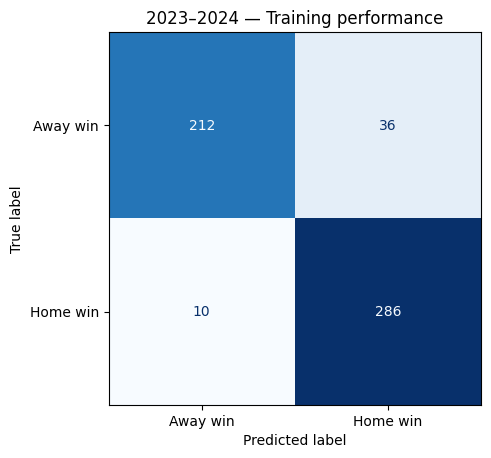


2025 — Held-out test performance
Accuracy: 0.590
Log loss: 0.708
Brier score: 0.253
ROC AUC: 0.622


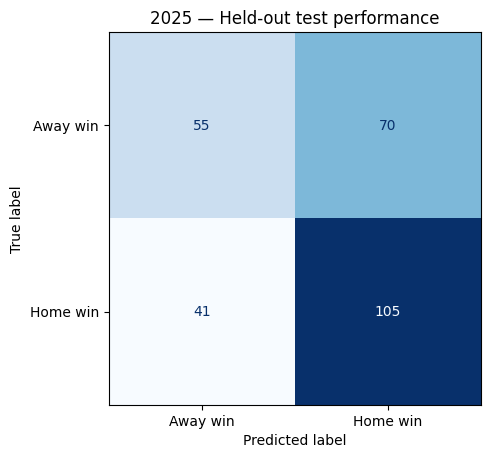

In [30]:
def evaluate_xgb(model, X, y, label):
    home_win_probability = model.predict_proba(X)[:, 1]
    predicted_winner = (home_win_probability >= 0.5).astype(int)

    print(f'\n{label}')
    print(f'Accuracy: {accuracy_score(y, predicted_winner):.3f}')
    print(
        f'Log loss: '
        f'{log_loss(y, home_win_probability, labels=[0, 1]):.3f}'
    )
    print(
        f'Brier score: '
        f'{brier_score_loss(y, home_win_probability):.3f}'
    )
    print(f'ROC AUC: {roc_auc_score(y, home_win_probability):.3f}')

    fig, ax = plt.subplots(figsize=(5, 5))

    ConfusionMatrixDisplay.from_predictions(
        y,
        predicted_winner,
        labels=[0, 1],
        display_labels=['Away win', 'Home win'],
        cmap='Blues',
        ax=ax,
        colorbar=False,
    )

    ax.set_title(label)
    plt.tight_layout()
    plt.show()

    return home_win_probability, predicted_winner


train_probability, train_prediction = evaluate_xgb(
    baselineXGBFound,
    X_development,
    y_development,
    '2023–2024 — Training performance',
)

test_probability, test_prediction = evaluate_xgb(
    baselineXGBFound,
    X_test,
    y_test,
    '2025 — Held-out test performance',
)


In [31]:
baseline_probability = np.full(
    len(y_test),
    y_development.mean(),
)

always_home_prediction = np.ones(len(y_test), dtype=int)

print(
    'Always-home baseline accuracy:',
    round(accuracy_score(y_test, always_home_prediction), 3)
)

print(
    'Historical home-win baseline log loss:',
    round(
        log_loss(y_test, baseline_probability, labels=[0, 1]),
        3
    )
)

test_results_2025 = model_2025.loc[
    X_test.index,
    ['Season', 'WeekNum', 'AwayTeam', 'HomeTeam', 'home_win']
].copy()

test_results_2025['home_win_probability'] = test_probability
test_results_2025['predicted_home_win'] = test_prediction

test_results_2025['predicted_winner'] = np.where(
    test_results_2025['predicted_home_win'].eq(1),
    test_results_2025['HomeTeam'],
    test_results_2025['AwayTeam'],
)

test_results_2025['correct'] = (
    test_results_2025['predicted_home_win']
    == test_results_2025['home_win']
)

display(test_results_2025.head(20))


Always-home baseline accuracy: 0.539
Historical home-win baseline log loss: 0.69


,Season,WeekNum,AwayTeam,HomeTeam,home_win,home_win_probability,predicted_home_win,predicted_winner,correct
0,2025,1,DAL,PHI,1,0.523955,1,PHI,True
1,2025,1,KC,LAC,1,0.523955,1,LAC,True
2,2025,1,TB,ATL,0,0.523955,1,ATL,False
3,2025,1,CIN,CLE,0,0.523955,1,CLE,False
4,2025,1,MIA,IND,1,0.523955,1,IND,True
5,2025,1,CAR,JAX,1,0.523955,1,JAX,True
6,2025,1,LV,NE,0,0.523955,1,NE,False
7,2025,1,ARI,NO,0,0.523955,1,NO,False
8,2025,1,PIT,NYJ,0,0.523955,1,NYJ,False
9,2025,1,NYG,WAS,1,0.523955,1,WAS,True


In [32]:
import json
from pathlib import Path
import nfl_model_pipeline as nfl

history_raw = nfl.load_team_stats(range(2020, 2026))
schedule_raw = nfl.load_schedule()
history_schedule = nfl.prepare_schedule(schedule_raw, 2020, 2025)


history_schedule = history_schedule.loc[history_schedule.completed].reset_index(drop=True)
display(nfl.reconcile_scores(history_schedule, {2023: df3, 2024: df2, 2025: df1}))
print('Raw team-stat columns retained:', history_raw.shape[1])
display(history_schedule.groupby('season').size().rename('completed_regular_games'))

enhanced_games, enhanced_team_features = nfl.build_pregame_features(history_schedule, history_raw)
development = enhanced_games.loc[enhanced_games.season.le(2024) & enhanced_games.home_win.notna()].copy()
benchmark_2025 = enhanced_games.loc[enhanced_games.season.eq(2025) & enhanced_games.home_win.notna()].copy()
assert set(development.game_id).isdisjoint(benchmark_2025.game_id)
assert development.gameday.max() < benchmark_2025.gameday.min()
assert len(benchmark_2025) == 271
print('Development:', len(development), 'games; 2025 benchmark:', len(benchmark_2025))


,season,games,scores_and_dates_match
0,2023,272,True
1,2024,272,True
2,2025,272,True


Raw team-stat columns retained: 138


season
2020    256
2021    272
2022    271
2023    272
2024    272
2025    272
Name: completed_regular_games, dtype: int64

Development: 1339 games; 2025 benchmark: 271


In [33]:
feature_groups = nfl.feature_sets()
for name, columns in feature_groups.items():
    assert len(columns) == len(set(columns))
    assert set(columns).issubset(development.columns)
    assert not any(c in columns for c in ['home_score', 'away_score', 'home_win', 'result', 'spread_line'])

folds = nfl.walk_forward_folds(development, first_validation_season=2022)
display(pd.DataFrame([
    {'validation': label, 'training_games': len(train), 'validation_games': len(valid),
     'last_training_date': development.loc[train, 'gameday'].max().date(),
     'first_validation_date': development.loc[valid, 'gameday'].min().date()}
    for label, train, valid in folds
]))

ablation_rows = []
for name in feature_groups:
    specification = {'candidate': name, 'feature_set': name, 'params': nfl.BASE_PARAMS,
                     'history_seasons': None, 'half_life': None}
    summary, _, _ = nfl.cross_validate_spec(development, folds, feature_groups, specification, seeds=(1, 7, 21))
    ablation_rows.append(summary)
feature_comparison = pd.DataFrame(ablation_rows).sort_values(['accuracy', 'log_loss'], ascending=[False, True])
display(feature_comparison[['feature_set', 'features', 'games', 'accuracy', 'log_loss', 'worst_fold_accuracy']])


,validation,training_games,validation_games,last_training_date,first_validation_date
0,2022 W1-9,526,135,2022-01-09,2022-09-08
1,2022 W10-18,661,134,2022-11-07,2022-11-10
2,2023 W1-9,795,136,2023-01-08,2023-09-07
3,2023 W10-18,931,136,2023-11-06,2023-11-09
4,2024 W1-9,1067,138,2024-01-07,2024-09-05
5,2024 W10-18,1205,134,2024-11-04,2024-11-07


,feature_set,features,games,accuracy,log_loss,worst_fold_accuracy
9,all_enhanced,55,813,0.645756,0.643781,0.585185
7,efficiency_recent8,41,813,0.635916,0.639818,0.588235
8,efficiency_turnovers,35,813,0.632226,0.642084,0.551471
5,efficiency_context,33,813,0.628536,0.642669,0.558824
6,efficiency_recent4,41,813,0.627306,0.644726,0.577778
0,original,27,813,0.605166,0.660215,0.555556
2,original_no_cold,26,813,0.605166,0.660816,0.540741
3,original_no_turnovers_cold,20,813,0.595326,0.660660,0.525926
4,efficiency_gaps,14,813,0.589176,0.654359,0.507353
1,original_no_turnovers,21,813,0.584256,0.659865,0.525926


In [34]:
candidates = nfl.make_candidates(feature_groups, samples_per_group=8)
print('Predeclared configurations:', len(candidates))
nested_results = nfl.nested_audit(development, feature_groups, candidates, test_seasons=(2023, 2024))
display(nested_results)

tuning = nfl.search_xgb(development, folds, feature_groups, candidates)
selected_spec = tuning['selected']
selected_features = feature_groups[selected_spec['feature_set']]
display(tuning['search_results'].head(10))
display(tuning['finalists'])
display(tuning['fold_results'])
print('Selected specification (before 2025 scoring):')
print(json.dumps(selected_spec, indent=2))
print('Selected predictors:', selected_features)


locked_spec_json = json.dumps(selected_spec, sort_keys=True)
tuned_xgb_models = nfl.fit_xgb(development, selected_features, selected_spec, seeds=(1, 7, 21))
logistic_features = feature_groups['efficiency_context']
logistic_model, logistic_tuning = nfl.logistic_baseline(development, folds, logistic_features)
display(logistic_tuning)


Predeclared configurations: 80
Nested audit 2023: 58.8% across 272 games
Nested audit 2024: 69.5% across 272 games


,season,candidate,games,correct,accuracy,log_loss,brier,roc_auc,always_home_accuracy,elo_accuracy
0,2023,efficiency_turnovers:0,272,160,0.588235,0.669370,0.238111,0.640852,0.555147,0.606618
1,2024,efficiency_context:7,272,189,0.694853,0.629898,0.219049,0.735813,0.533088,0.650735


Completed 20/80 chronological search trials
Completed 40/80 chronological search trials
Completed 60/80 chronological search trials
Completed 80/80 chronological search trials


,candidate,feature_set,features,games,correct,accuracy,log_loss,brier,roc_auc,worst_fold_accuracy,fold_accuracy_sd,seeds
0,efficiency_context:7,efficiency_context,33,813,535,0.658057,0.646019,0.226875,0.683173,0.617647,0.039600,1
1,efficiency_turnovers:7,efficiency_turnovers,35,813,535,0.658057,0.646019,0.226875,0.683173,0.617647,0.039600,1
2,all_enhanced:7,all_enhanced,55,813,534,0.656827,0.646057,0.226918,0.680881,0.548148,0.064357,1
3,efficiency_recent4:7,efficiency_recent4,41,813,531,0.653137,0.646565,0.227138,0.680591,0.602941,0.049654,1
4,efficiency_recent8:7,efficiency_recent8,41,813,530,0.651907,0.645122,0.226469,0.685719,0.548148,0.063416,1
5,efficiency_recent8:0,efficiency_recent8,41,813,525,0.645756,0.640084,0.224755,0.677541,0.588235,0.047651,1
6,all_enhanced:0,all_enhanced,55,813,521,0.640836,0.645664,0.226867,0.670255,0.562963,0.061449,1
7,efficiency_recent8:1,efficiency_recent8,41,813,521,0.640836,0.649506,0.228383,0.668962,0.577778,0.048115,1
8,all_enhanced:4,all_enhanced,55,813,521,0.640836,0.657696,0.231624,0.662956,0.580882,0.046366,1
9,efficiency_recent8:6,efficiency_recent8,41,813,520,0.639606,0.656125,0.231529,0.661648,0.595588,0.040280,1


,candidate,feature_set,features,games,correct,accuracy,log_loss,brier,roc_auc,worst_fold_accuracy,fold_accuracy_sd,seeds
0,efficiency_context:7,efficiency_context,33,813,536,0.659287,0.646688,0.227205,0.683140,0.617647,0.044297,3
1,efficiency_turnovers:7,efficiency_turnovers,35,813,536,0.659287,0.646688,0.227205,0.683140,0.617647,0.044297,3
2,efficiency_recent4:7,efficiency_recent4,41,813,526,0.646986,0.647548,0.227626,0.680328,0.570370,0.056223,3
3,efficiency_recent8:7,efficiency_recent8,41,813,524,0.644526,0.645918,0.226856,0.684866,0.540741,0.062000,3
4,all_enhanced:7,all_enhanced,55,813,523,0.643296,0.647148,0.227453,0.680817,0.533333,0.066191,3


,fold,games,correct,accuracy,log_loss,brier,roc_auc
0,2022 W1-9,135,85,0.629630,0.670107,0.238583,0.631684
1,2022 W10-18,134,92,0.686567,0.634846,0.221393,0.733516
2,2023 W1-9,136,87,0.639706,0.644505,0.226192,0.691913
3,2023 W10-18,136,84,0.617647,0.669402,0.238249,0.618860
4,2024 W1-9,138,88,0.637681,0.657150,0.232256,0.667758
5,2024 W10-18,134,100,0.746269,0.603321,0.206174,0.793874


Selected specification (before 2025 scoring):
{
  "candidate": "efficiency_context:7",
  "feature_set": "efficiency_context",
  "params": {
    "subsample": 0.75,
    "reg_lambda": 40.0,
    "reg_alpha": 2.0,
    "n_estimators": 50,
    "min_child_weight": 5,
    "max_depth": 1,
    "learning_rate": 0.04,
    "gamma": 2.0,
    "colsample_bytree": 1.0
  },
  "history_seasons": 5,
  "half_life": null
}
Selected predictors: ['gap_avg_points_for', 'gap_avg_points_against', 'gap_avg_pass_epa_rate', 'gap_avg_rush_epa_rate', 'gap_avg_def_pass_epa_allowed', 'gap_avg_def_rush_epa_allowed', 'gap_avg_passing_cpoe', 'gap_avg_sack_allowed_rate', 'gap_avg_sack_made_rate', 'gap_avg_first_down_rate', 'gap_avg_def_first_down_allowed', 'net_scoring_gap_avg', 'net_pass_epa_gap_avg', 'net_rush_epa_gap_avg', 'elo_gap', 'rest_gap', 'neutral_site', 'home_prior_games', 'away_prior_games', 'home_avg_points_for', 'home_avg_points_against', 'home_avg_pass_epa_rate', 'home_avg_rush_epa_rate', 'home_avg_def_pass_e

,C,games,correct,accuracy,log_loss,brier,roc_auc
1,0.10,813,524,0.644526,0.647203,0.227142,0.676605
3,10.00,813,522,0.642066,0.648997,0.227587,0.678164
0,0.01,813,521,0.640836,0.645521,0.226887,0.674338
2,1.00,813,521,0.640836,0.648976,0.227612,0.677895


,model,games,correct,accuracy,log_loss,brier,roc_auc
0,Original XGBoost (2023-2024 training),271,160,0.590406,0.707830,0.252889,0.621781
1,Tuned XGBoost (three-seed average),271,169,0.623616,0.647060,0.227530,0.679644
2,Regularized logistic regression,271,173,0.638376,0.635697,0.223476,0.683397
3,Pregame Elo baseline,271,173,0.638376,0.643642,0.226264,0.681205
4,Historical home-win probability,271,146,0.538745,0.690203,0.248529,0.500000


Always-home accuracy: 0.5387
NEW XGBOOST 2025 ACCURACY: 62.36%
Original versus new, paired week-bootstrap interval:


accuracy_difference    0.033210
lower_95              -0.041202
upper_95               0.101827
dtype: float64

,games,accuracy
week,,
1,16,0.687500
2,16,0.750000
3,16,0.687500
4,15,0.600000
5,14,0.357143
6,15,0.600000
7,15,0.733333
8,13,0.692308
9,14,0.571429


Secondary Weeks 2-18 XGBoost results: {'games': 255, 'correct': 158, 'accuracy': 0.6196078431372549, 'log_loss': 0.6474582036111382, 'brier': 0.22774660043144246, 'roc_auc': 0.6788630458987999}


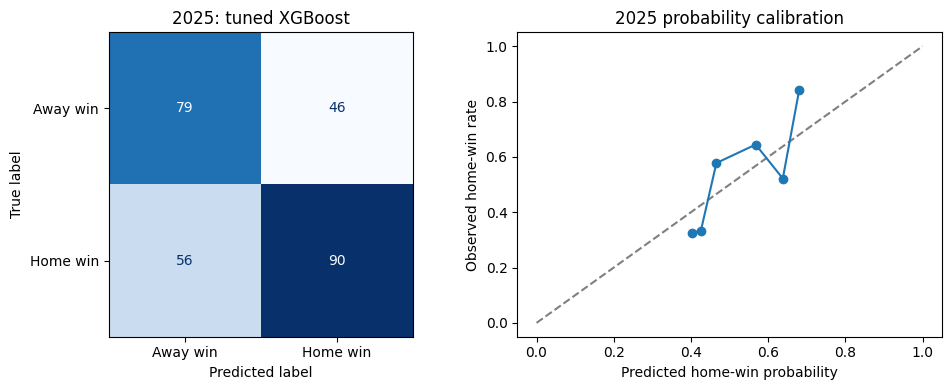

In [35]:
assert locked_spec_json == json.dumps(selected_spec, sort_keys=True)
new_probability_2025 = nfl.predict_models(tuned_xgb_models, benchmark_2025, selected_features)
logistic_probability_2025 = logistic_model.predict_proba(benchmark_2025[logistic_features])[:, 1]
original_by_game = pd.Series(test_probability, index=model_2025.loc[X_test.index, 'game_id'])
original_probability_2025 = benchmark_2025.game_id.map(original_by_game).to_numpy()
assert np.isfinite(original_probability_2025).all()
probability_baseline = np.full(len(benchmark_2025), development.home_win.mean())

comparison_probabilities = {
    'Original XGBoost (2023-2024 training)': original_probability_2025,
    'Tuned XGBoost (three-seed average)': new_probability_2025,
    'Regularized logistic regression': logistic_probability_2025,
    'Pregame Elo baseline': benchmark_2025.elo_home_probability.to_numpy(),
    'Historical home-win probability': probability_baseline,
}
benchmark_results = pd.DataFrame([
    {'model': name, **nfl.metrics(benchmark_2025.home_win, probability)}
    for name, probability in comparison_probabilities.items()
])
display(benchmark_results)
print('Always-home accuracy:', round(benchmark_2025.home_win.mean(), 4))
print('NEW XGBOOST 2025 ACCURACY:', f'{nfl.metrics(benchmark_2025.home_win, new_probability_2025)["accuracy"]:.2%}')
print('Original versus new, paired week-bootstrap interval:')
display(pd.Series(nfl.block_bootstrap_difference(
    benchmark_2025.home_win, new_probability_2025, original_probability_2025, benchmark_2025.week
)))

test_results_2025_improved = benchmark_2025[['game_id', 'season', 'week', 'home_team', 'away_team', 'home_win']].copy()
test_results_2025_improved['home_win_probability'] = new_probability_2025
test_results_2025_improved['predicted_winner'] = np.where(new_probability_2025 >= .5, benchmark_2025.home_team, benchmark_2025.away_team)
test_results_2025_improved['correct'] = (new_probability_2025 >= .5) == benchmark_2025.home_win
display(test_results_2025_improved.groupby('week').agg(games=('correct', 'size'), accuracy=('correct', 'mean')))
after_week_one = benchmark_2025.week.gt(1).to_numpy()
print('Secondary Weeks 2-18 XGBoost results:', nfl.metrics(
    benchmark_2025.loc[after_week_one, 'home_win'], new_probability_2025[after_week_one]
))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(benchmark_2025.home_win, new_probability_2025 >= .5,
    display_labels=['Away win', 'Home win'], ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('2025: tuned XGBoost')
from sklearn.calibration import calibration_curve
observed, predicted = calibration_curve(benchmark_2025.home_win, new_probability_2025, n_bins=6, strategy='quantile')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].plot(predicted, observed, 'o-')
axes[1].set(xlabel='Predicted home-win probability', ylabel='Observed home-win rate', title='2025 probability calibration')
plt.tight_layout()
plt.show()


In [36]:
assert locked_spec_json == json.dumps(selected_spec, sort_keys=True)
all_completed = enhanced_games.loc[enhanced_games.home_win.notna()].copy()
deployment_models = nfl.fit_xgb(all_completed, selected_features, selected_spec, seeds=(1, 7, 21))
benchmark_bundle_path = nfl.save_model_bundle(tuned_xgb_models, selected_features, selected_spec, development)
deployment_bundle_path = nfl.save_model_bundle(deployment_models, selected_features, selected_spec, all_completed)
print('Benchmark model:', benchmark_bundle_path)
print('Deployment model:', deployment_bundle_path)

artifacts = Path('model_artifacts')
feature_comparison.to_json(artifacts / 'feature_comparison.json', orient='records', indent=2)
nested_results.to_json(artifacts / 'nested_audit.json', orient='records', indent=2)
tuning['search_results'].to_json(artifacts / 'search_results.json', orient='records', indent=2)
tuning['finalists'].to_json(artifacts / 'finalists.json', orient='records', indent=2)
benchmark_results.to_json(artifacts / 'benchmark_2025.json', orient='records', indent=2)
test_results_2025_improved.to_json(artifacts / 'predictions_2025.json', orient='records', indent=2)
print('Saved model specifications, feature comparisons, audit results, and benchmark predictions.')


Benchmark model: model_artifacts/nfl_xgb_b7666dbbb191.joblib
Deployment model: model_artifacts/nfl_xgb_24b9fc23fae6.joblib
Saved model specifications, feature comparisons, audit results, and benchmark predictions.


## Week 5 predictions 


In [37]:
from pathlib import Path
import nfl_model_pipeline as nfl

prediction_season, prediction_week = 2026, 5
week5_model_path = Path("model_artifacts/nfl_xgb_24b9fc23fae6.joblib")

# Refresh only current data. Historical caches and fitted model stay fixed.
week5_schedule = nfl.load_schedule(refresh=True)
week5_raw = nfl.load_team_stats([prediction_season], refresh=True)
week5_games = nfl.prepare_schedule(week5_schedule, prediction_season, prediction_season)
week4_games = week5_games.loc[week5_games.week.eq(prediction_week - 1)]
week4_stats = week5_raw.loc[week5_raw.week.eq(prediction_week - 1) & week5_raw.season_type.eq("REG")]
print(f"Week 4: {int(week4_games.completed.sum())}/{len(week4_games)} games completed; "
      f"statistics available for {week4_stats.game_id.nunique()} games.")

# The pipeline refuses incomplete earlier games or missing team statistics,
# excludes started games, and constructs inputs using prior weeks only.
week5_predictions, week5_inputs = nfl.predict_upcoming_week(
    week5_model_path, prediction_season, prediction_week,
    refresh=False, log=False, return_features=True,
)
week5_preview = week5_predictions.copy()
week5_preview["winner_probability"] = week5_preview.home_win_probability.where(
    week5_preview.predicted_winner.eq(week5_preview.home_team),
    1 - week5_preview.home_win_probability,
)
print(f"Ready: {len(week5_preview)} upcoming Week 5 games. Preview only; no picks saved.")
display(week5_preview[["gameday", "away_team", "home_team", "predicted_winner", "winner_probability"]]
        .style.format({"winner_probability": "{:.1%}"}))


Week 4: 16/16 games completed; statistics available for 16 games.
Ready: 15 upcoming Week 5 games. Preview only; no picks saved.


,gameday,away_team,home_team,predicted_winner,winner_probability
1679,2026-10-08 00:00:00,TB,DAL,DAL,65.1%
1680,2026-10-11 00:00:00,BAL,ATL,BAL,58.4%
1681,2026-10-11 00:00:00,CHI,GB,CHI,58.3%
1682,2026-10-11 00:00:00,CIN,MIA,CIN,58.7%
1683,2026-10-11 00:00:00,CLE,NYJ,CLE,56.9%
1684,2026-10-11 00:00:00,DEN,LAC,DEN,56.9%
1685,2026-10-11 00:00:00,DET,ARI,DET,57.0%
1686,2026-10-11 00:00:00,HOU,TEN,HOU,55.4%
1687,2026-10-11 00:00:00,IND,PIT,PIT,56.4%
1688,2026-10-11 00:00:00,LV,NE,NE,61.1%


In [38]:
from nfl_app_launcher import launch_nfl_app, stop_nfl_app

app_url = launch_nfl_app()
print(f"Week 5 NFL predictor: {app_url}")
print("To stop the local server, run: stop_nfl_app()")


Week 5 NFL predictor: http://127.0.0.1:8501
To stop the local server, run: stop_nfl_app()
